   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 100.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 105.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.7/530.7 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.3/188.3 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Dataset shape: (25001, 2)

First 5 rows:


,review,sentiment
0,0,1
1,I did not enjoy the film Eraser whatsoever. It...,0
2,Be very afraid of anyone who likes this film. ...,0
3,The 3rd and last big screen spin off from the ...,0
4,Barely three and a half years after just scrap...,1



Column names: ['review', 'sentiment']

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 199

Class distribution:
sentiment
1    12501
0    12500
Name: count, dtype: int64


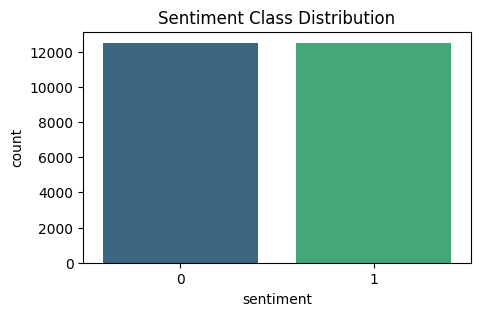

In [ ]:
# Cell 1: Setup + Load Dataset + Basic Inspection

# Install required packages (safe for Colab/Jupyter; skip if already installed)
!pip -q install nltk gensim scikit-learn tensorflow transformers torch --upgrade

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

# Load dataset
df = pd.read_csv("test_data.csv", header=None)

# Rename columns
df.columns = ["review", "sentiment"]

# Basic checks
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["sentiment"].value_counts())

# Optional quick visualization
plt.figure(figsize=(5, 3))
sns.countplot(x="sentiment", data=df, palette="viridis")
plt.title("Sentiment Class Distribution")
plt.show()

In [ ]:
# Cell 2: Text Preprocessing (fixed for punkt_tab issue)

import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
import re
import string

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and apply stemming
    tokens = [stemmer.stem(word) for word in tokens if word not in stop_words and len(word) > 2]

    return " ".join(tokens), tokens

# Apply preprocessing
df["clean_review"], df["tokens"] = zip(*df["review"].apply(preprocess_text))

# Preview results
print("Original Review:\n")
print(df.loc[0, "review"])

print("\nCleaned Review:\n")
print(df.loc[0, "clean_review"])

print("\nTop 5 rows after preprocessing:")
display(df[["review", "clean_review", "sentiment"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Original Review:

0

Cleaned Review:



Top 5 rows after preprocessing:


,review,clean_review,sentiment
0,0,,1
1,I did not enjoy the film Eraser whatsoever. It...,enjoy film eras whatsoev aw act bore storylin ...,0
2,Be very afraid of anyone who likes this film. ...,afraid anyon like film probabl inhal mani pain...,0
3,The 3rd and last big screen spin off from the ...,last big screen spin popular itv sitcom earli ...,0
4,Barely three and a half years after just scrap...,bare three half year scrape month run oct broa...,1


In [ ]:
# Cell 3: Train-Test Split + TF-IDF Vectorization

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Features and labels
X = df["clean_review"]
y = df["sentiment"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF test shape :", X_test_tfidf.shape)

# Preview a few feature names
feature_names = tfidf.get_feature_names_out()
print("\nSample TF-IDF features:")
print(feature_names[:20])

Training samples: 20000
Testing samples : 5001

TF-IDF train shape: (20000, 5000)
TF-IDF test shape : (5001, 5000)

Sample TF-IDF features:
['aaron' 'abandon' 'abc' 'abil' 'abl' 'absenc' 'absent' 'absolut'
 'absolut noth' 'absorb' 'absurd' 'abus' 'abysm' 'academi' 'academi award'
 'accent' 'accept' 'access' 'accid' 'accident']


In [5]:
# Cell 4: Train Naive Bayes Model + Evaluation

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluation
nb_accuracy = accuracy_score(y_test, y_pred_nb)
print("Naive Bayes Accuracy:", round(nb_accuracy, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_nb))

print("\nConfusion Matrix:\n")
cm_nb = confusion_matrix(y_test, y_pred_nb)
print(cm_nb)

Naive Bayes Accuracy: 0.8634

Classification Report:

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      2500
           1       0.85      0.88      0.87      2501

    accuracy                           0.86      5001
   macro avg       0.86      0.86      0.86      5001
weighted avg       0.86      0.86      0.86      5001


Confusion Matrix:

[[2128  372]
 [ 311 2190]]


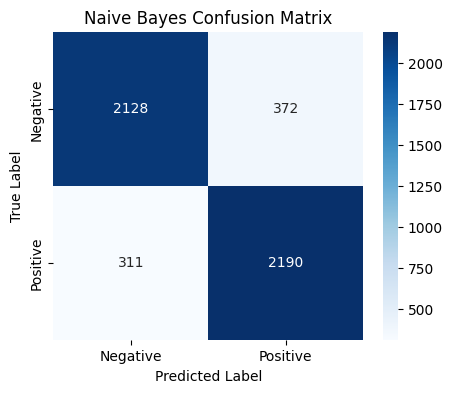

Sample Predictions:


,review,actual,predicted
0,tesi open eye other proof amenabar talent skil...,1,1
1,eastern right border northern new jersey still...,1,1
2,aw movi dont know horror film drama caus stori...,0,0
3,dont realli know start herejust imagin movi ba...,0,0
4,outstand film best act youll ever see alon mak...,1,1
5,pretti lame aw slasher someon kill member high...,0,1
6,ive never read good review vaniti fair cant un...,1,0
7,cheap pound shop openedi thought worth look se...,0,1
8,okay let cut chase there way give anyth yet se...,0,0
9,first glanc mini bit disappoint tommi lee jone...,1,1


In [6]:
# Cell 5: Confusion Matrix Plot + Sample Predictions

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

# Show sample predictions
sample_results = pd.DataFrame({
    "review": X_test.iloc[:10].values,
    "actual": y_test.iloc[:10].values,
    "predicted": y_pred_nb[:10]
})

print("Sample Predictions:")
display(sample_results)

In [7]:
# Cell 6: Word2Vec Feature Creation

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
import numpy as np

# Use tokenized reviews
X_tokens = df["tokens"]
y = df["sentiment"]

# Train-test split for token data
X_train_tok, X_test_tok, y_train_w2v, y_test_w2v = train_test_split(
    X_tokens, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training token samples:", len(X_train_tok))
print("Testing token samples :", len(X_test_tok))

# Train Word2Vec model on training tokens only
w2v_model = Word2Vec(
    sentences=X_train_tok,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# Function to average word vectors for a review
def document_vector(tokens, model):
    valid_words = [word for word in tokens if word in model.wv]
    if len(valid_words) == 0:
        return np.zeros(model.vector_size)
    return np.mean(model.wv[valid_words], axis=0)

# Convert each review into a fixed-length vector
X_train_w2v = np.array([document_vector(tokens, w2v_model) for tokens in X_train_tok])
X_test_w2v = np.array([document_vector(tokens, w2v_model) for tokens in X_test_tok])

print("Word2Vec train shape:", X_train_w2v.shape)
print("Word2Vec test shape :", X_test_w2v.shape)
print("Vector size:", w2v_model.vector_size)

Training token samples: 20000
Testing token samples : 5001
Word2Vec train shape: (20000, 100)
Word2Vec test shape : (5001, 100)
Vector size: 100


In [8]:
# Cell 7: Train Classifier on Word2Vec Features + Evaluation

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train classifier
lr_w2v_model = LogisticRegression(max_iter=1000)
lr_w2v_model.fit(X_train_w2v, y_train_w2v)

# Predictions
y_pred_w2v = lr_w2v_model.predict(X_test_w2v)

# Evaluation
w2v_accuracy = accuracy_score(y_test_w2v, y_pred_w2v)
print("Word2Vec + Logistic Regression Accuracy:", round(w2v_accuracy, 4))

print("\nClassification Report:\n")
print(classification_report(y_test_w2v, y_pred_w2v))

print("\nConfusion Matrix:\n")
cm_w2v = confusion_matrix(y_test_w2v, y_pred_w2v)
print(cm_w2v)

Word2Vec + Logistic Regression Accuracy: 0.8692

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.86      0.87      2500
           1       0.86      0.88      0.87      2501

    accuracy                           0.87      5001
   macro avg       0.87      0.87      0.87      5001
weighted avg       0.87      0.87      0.87      5001


Confusion Matrix:

[[2144  356]
 [ 298 2203]]


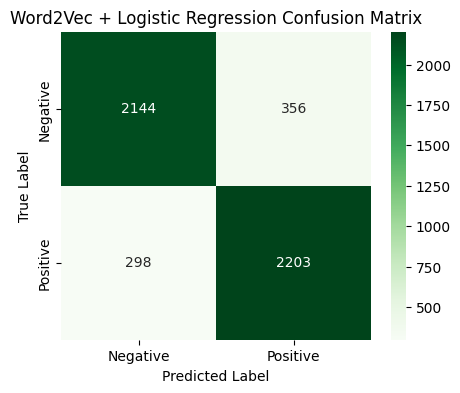

Model Comparison:


,Model,Accuracy
0,Naive Bayes + TF-IDF,0.863427
1,Logistic Regression + Word2Vec,0.869226


In [9]:
# Cell 8: Word2Vec Confusion Matrix + Model Comparison

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

# Confusion matrix for Word2Vec model
cm_w2v = confusion_matrix(y_test_w2v, y_pred_w2v)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_w2v, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Word2Vec + Logistic Regression Confusion Matrix")
plt.show()

# Compare models
comparison_df = pd.DataFrame({
    "Model": ["Naive Bayes + TF-IDF", "Logistic Regression + Word2Vec"],
    "Accuracy": [nb_accuracy, w2v_accuracy]
})

print("Model Comparison:")
display(comparison_df)

In [10]:
# Cell 9: Prepare Data for LSTM

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import numpy as np

# Use cleaned review text
X_lstm = df["clean_review"].values
y_lstm = df["sentiment"].values

# Train-test split
X_train_lstm_text, X_test_lstm_text, y_train_lstm, y_test_lstm = train_test_split(
    X_lstm, y_lstm,
    test_size=0.2,
    random_state=42,
    stratify=y_lstm
)

# Tokenizer settings
max_words = 10000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_lstm_text)

# Convert text to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_lstm_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_lstm_text)

# Pad sequences
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post", truncating="post")

print("X_train_pad shape:", X_train_pad.shape)
print("X_test_pad shape :", X_test_pad.shape)
print("Vocabulary size  :", min(max_words, len(tokenizer.word_index) + 1))
print("Max sequence len :", max_len)

X_train_pad shape: (20000, 200)
X_test_pad shape : (5001, 200)
Vocabulary size  : 10000
Max sequence len : 200


In [11]:
# Cell 10: Build and Train LSTM Model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

vocab_size = min(max_words, len(tokenizer.word_index) + 1)

lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=max_len),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

lstm_model.summary()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_pad, y_train_lstm,
    validation_split=0.2,
    epochs=5,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 87s 324ms/step - accuracy: 0.5026 - loss: 0.6933 - val_accuracy: 0.5077 - val_loss: 0.6909
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 78s 312ms/step - accuracy: 0.5343 - loss: 0.6829 - val_accuracy: 0.5247 - val_loss: 0.6879
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 81s 309ms/step - accuracy: 0.5524 - loss: 0.6450 - val_accuracy: 0.5280 - val_loss: 0.6884
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 76s 306ms/step - accuracy: 0.5656 - loss: 0.6169 - val_accuracy: 0.5280 - val_loss: 0.7113


157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step
LSTM Accuracy: 0.5217

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.06      0.11      2500
           1       0.51      0.99      0.67      2501

    accuracy                           0.52      5001
   macro avg       0.66      0.52      0.39      5001
weighted avg       0.66      0.52      0.39      5001



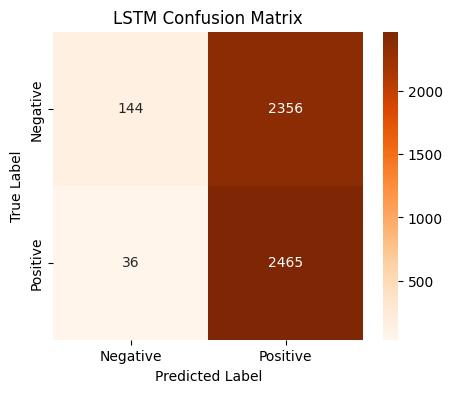

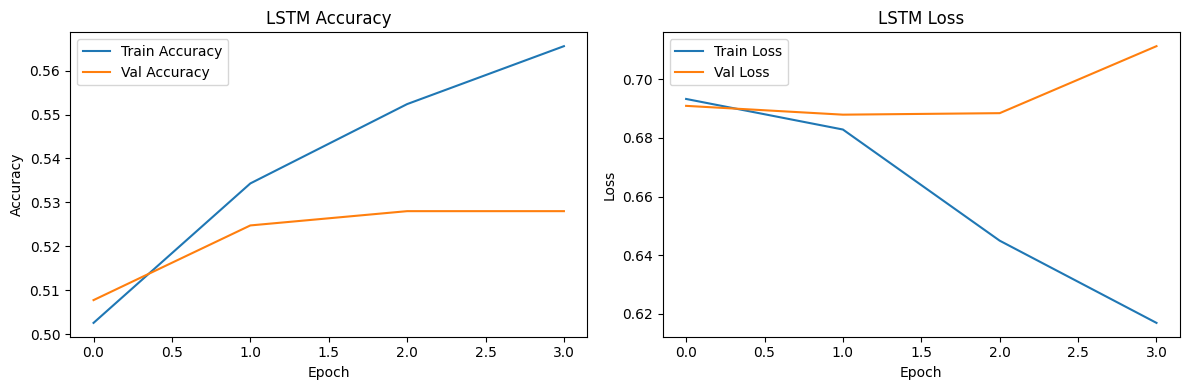

In [12]:
# Cell 11: Evaluate LSTM Model + Plot Training History

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict probabilities and convert to binary labels
y_pred_lstm_prob = lstm_model.predict(X_test_pad)
y_pred_lstm = (y_pred_lstm_prob > 0.5).astype("int32")

# Accuracy
lstm_accuracy = accuracy_score(y_test_lstm, y_pred_lstm)
print("LSTM Accuracy:", round(lstm_accuracy, 4))

print("\nClassification Report:\n")
print(classification_report(y_test_lstm, y_pred_lstm))

# Confusion Matrix
cm_lstm = confusion_matrix(y_test_lstm, y_pred_lstm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_lstm, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("LSTM Confusion Matrix")
plt.show()

# Training history plots
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
# Cell 12: BERT Tokenization + Dataset Preparation

from sklearn.model_selection import train_test_split
from transformers import BertTokenizer
import torch

# Use original review text for BERT
X_bert = df["review"].astype(str).values
y_bert = df["sentiment"].values

# Train-test split
X_train_bert, X_test_bert, y_train_bert, y_test_bert = train_test_split(
    X_bert, y_bert,
    test_size=0.2,
    random_state=42,
    stratify=y_bert
)

print("BERT training samples:", len(X_train_bert))
print("BERT testing samples :", len(X_test_bert))

# Load tokenizer
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Tokenize text
train_encodings = bert_tokenizer(
    list(X_train_bert),
    truncation=True,
    padding=True,
    max_length=256
)

test_encodings = bert_tokenizer(
    list(X_test_bert),
    truncation=True,
    padding=True,
    max_length=256
)

# Custom PyTorch Dataset
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = SentimentDataset(train_encodings, y_train_bert)
test_dataset = SentimentDataset(test_encodings, y_test_bert)

print("Train dataset size:", len(train_dataset))
print("Test dataset size :", len(test_dataset))

BERT training samples: 20000
BERT testing samples : 5001


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Train dataset size: 20000
Test dataset size : 5001


In [16]:
# Cell 13 (ULTRA-FAST): Presentation Version

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import torch
import numpy as np

# Small subset for presentation
train_size_small = 1000
test_size_small = 300

X_train_small, _, y_train_small, _ = train_test_split(
    X_train_bert, y_train_bert,
    train_size=train_size_small,
    random_state=42,
    stratify=y_train_bert
)

X_test_small, _, y_test_small, _ = train_test_split(
    X_test_bert, y_test_bert,
    train_size=test_size_small,
    random_state=42,
    stratify=y_test_bert
)

model_name = "distilbert-base-uncased"
tokenizer_fast = AutoTokenizer.from_pretrained(model_name)

train_encodings_fast = tokenizer_fast(
    list(X_train_small),
    truncation=True,
    padding=True,
    max_length=64
)

test_encodings_fast = tokenizer_fast(
    list(X_test_small),
    truncation=True,
    padding=True,
    max_length=64
)

class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

train_dataset_fast = SentimentDataset(train_encodings_fast, y_train_small)
test_dataset_fast = SentimentDataset(test_encodings_fast, y_test_small)

fast_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Freeze transformer body for speed; train only classifier layers
for param in fast_model.distilbert.parameters():
    param.requires_grad = False

def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    acc = accuracy_score(labels, preds)
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

use_fp16 = torch.cuda.is_available()
batch_size = 32 if torch.cuda.is_available() else 8

training_args_fast = TrainingArguments(
    output_dir="./ultra_fast_results",
    eval_strategy="no",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=1,
    logging_steps=10,
    report_to="none",
    fp16=use_fp16
)

trainer_fast = Trainer(
    model=fast_model,
    args=training_args_fast,
    train_dataset=train_dataset_fast,
    eval_dataset=test_dataset_fast,
    compute_metrics=compute_metrics
)

trainer_fast.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
10,0.683447
20,0.719579
30,0.686254
40,0.711789
50,0.693576
60,0.704481
70,0.695211
80,0.694101
90,0.699407
100,0.701536


TrainOutput(global_step=125, training_loss=0.6975122108459473, metrics={'train_runtime': 121.222, 'train_samples_per_second': 8.249, 'train_steps_per_second': 1.031, 'total_flos': 16558424832000.0, 'train_loss': 0.6975122108459473, 'epoch': 1.0})

Fast Transformer Accuracy: 0.5033

Classification Report:

              precision    recall  f1-score   support

           0       0.50      1.00      0.67       150
           1       1.00      0.01      0.01       150

    accuracy                           0.50       300
   macro avg       0.75      0.50      0.34       300
weighted avg       0.75      0.50      0.34       300



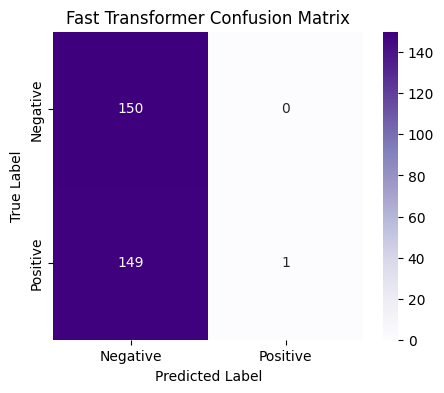

Final Model Comparison:


,Model,Accuracy
0,Logistic Regression + Word2Vec,0.869226
1,Naive Bayes + TF-IDF,0.863427
2,LSTM,0.521696
3,Fast Transformer,0.503333


In [17]:
# Cell 14: Evaluate Fast Transformer + Final Comparison

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Predictions
pred_output = trainer_fast.predict(test_dataset_fast)
y_pred_bert = np.argmax(pred_output.predictions, axis=1)

# Metrics
bert_accuracy = accuracy_score(y_test_small, y_pred_bert)
print("Fast Transformer Accuracy:", round(bert_accuracy, 4))

print("\nClassification Report:\n")
print(classification_report(y_test_small, y_pred_bert))

# Confusion matrix
cm_bert = confusion_matrix(y_test_small, y_pred_bert)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fast Transformer Confusion Matrix")
plt.show()

# Final comparison table
final_comparison = pd.DataFrame({
    "Model": [
        "Naive Bayes + TF-IDF",
        "Logistic Regression + Word2Vec",
        "LSTM",
        "Fast Transformer"
    ],
    "Accuracy": [
        nb_accuracy,
        w2v_accuracy,
        lstm_accuracy,
        bert_accuracy
    ]
})

print("Final Model Comparison:")
display(final_comparison.sort_values(by="Accuracy", ascending=False).reset_index(drop=True))

In [18]:
# Cell 15: Test Custom Review Sentiment

def preprocess_for_prediction(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    tokens = [stemmer.stem(word) for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(tokens)

# Try your own review here
custom_review = "This movie was absolutely amazing, the acting and storyline were brilliant."

# Preprocess and transform
clean_custom_review = preprocess_for_prediction(custom_review)
custom_vector = tfidf.transform([clean_custom_review])

# Predict
prediction = nb_model.predict(custom_vector)[0]
label = "Positive" if prediction == 1 else "Negative"

print("Custom Review:")
print(custom_review)

print("\nPredicted Sentiment:", label)

Custom Review:
This movie was absolutely amazing, the acting and storyline were brilliant.

Predicted Sentiment: Positive
